In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Depth check - does a 4th conv block help? Kernels 3 everywhere,
# same training settings as the filter check.

import os, glob, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models

DATA_DIR = "/content/drive/MyDrive/XPQRS"
OUTPUT_DIR = "/content/drive/MyDrive/XPQRS/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
FOLDS = 3               # 3 = comparable with the earlier ablation; will use 5 for the final confirmation
EPOCHS = 40
RUN_FINAL_TEST = False  # True only when we are ready to test the best model on the locked 20%

COMPOUND_CLASSES = {
    "Flicker_with_Sag", "Flicker_with_Swell", "Harmonics_with_Sag",
    "Harmonics_with_Swell", "Sag_with_Harmonics", "Sag_with_Oscillatory_Transient",
    "Swell_with_Harmonics", "Swell_with_Oscillatory_Transient",
}

def set_seed(s=RANDOM_STATE):
    np.random.seed(s); random.seed(s); tf.random.set_seed(s)
set_seed()

In [ ]:
signals, labels = [], []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    label = os.path.splitext(os.path.basename(path))[0]
    data = pd.read_csv(path, header=None)
    signals.append(data.values.astype(np.float32))
    labels.extend([label] * len(data))

X_raw = np.vstack(signals)
y = np.array(labels)
classes = sorted(np.unique(y))
y_enc = LabelEncoder().fit(classes).transform(y)
is_compound = np.array([c in COMPOUND_CLASSES for c in classes])
N_SAMPLES = X_raw.shape[1]
X_all = X_raw.reshape(-1, N_SAMPLES, 1)

# Same 80/20 split as PQD_Code.py (same seed + stratify), so the
# test set here is the same 3400 signals. Only the 80% pool is used
# for choosing settings - test set stays locked until the end.

tv_path, te_path = f"{OUTPUT_DIR}/trainval_idx.npy", f"{OUTPUT_DIR}/test_idx.npy"
if os.path.exists(tv_path) and os.path.exists(te_path):
    trainval_idx, test_idx = np.load(tv_path), np.load(te_path)
    print("Loaded saved split")
else:
    trainval_idx, test_idx = train_test_split(np.arange(len(y)), test_size=TEST_SIZE,
                                              random_state=RANDOM_STATE, stratify=y)
    print("Recreated the same 80/20 split")
print(f"Pool: {len(trainval_idx)} signals | locked test set: {len(test_idx)} (not used in this search)")

Recreated the same 80/20 split
Pool: 13600 signals | locked test set: 3400 (not used in this search)


In [ ]:
# Same as before but number of blocks = len(filters), so we can
# pass 4 filter sizes to get 4 blocks.

def build_model(n_classes, n_samples, filters=(32, 64, 128), kernel_sizes=None):
    """Depth = len(filters). Kernel size 3 in every block. Only filters/depth vary in this notebook."""
    if kernel_sizes is None:
        kernel_sizes = (3,) * len(filters)
    n_blocks = len(filters)
    x_in = layers.Input(shape=(n_samples, 1))
    x = x_in
    for i in range(n_blocks):
        x = layers.Conv1D(filters[i], kernel_size=kernel_sizes[i], activation="relu", padding="same")(x)
        x = layers.BatchNormalization()(x)
        if i < n_blocks - 1:
            x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = models.Model(x_in, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ]
    
# For each fold: train on 2/3 of the pool, score on the other 1/3.
# Inside the training part we take another 15% out just for early
# stopping, so the fold we score on is never seen during training.
# clear_session + set_seed every time so every setting starts from
# the same weights - otherwise we'd just be comparing luck.

def evaluate_filters(filters, n_folds=FOLDS):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    accs, f1s, n_params = [], [], None
    for tr, va in skf.split(trainval_idx, y[trainval_idx]):
        tr_idx, va_idx = trainval_idx[tr], trainval_idx[va]
        fit_idx, es_idx = train_test_split(tr_idx, test_size=0.15, random_state=RANDOM_STATE,
                                           stratify=y[tr_idx])
        tf.keras.backend.clear_session(); set_seed()
        m = build_model(len(classes), N_SAMPLES, filters=filters)
        n_params = m.count_params()
        m.fit(X_all[fit_idx], y_enc[fit_idx], validation_data=(X_all[es_idx], y_enc[es_idx]),
              epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=0)
        pred = np.argmax(m.predict(X_all[va_idx], verbose=0), axis=1)
        accs.append(accuracy_score(y_enc[va_idx], pred) * 100)
        f1s.append(f1_score(y_enc[va_idx], pred, labels=range(len(classes)), average=None, zero_division=0))
    return np.array(accs), np.array(f1s).mean(axis=0), n_params

In [ ]:
FILTERS = {
    "4 blocks 32-64-128-128": (32, 64, 128, 128),
    "4 blocks 32-64-128-256": (32, 64, 128, 256),
}
# Reference: the 3-block 32/64/128 model (kernels 3-3-3) from the filter test, same folds and seed
# Not re-running the 3-block model, just using its number from the
# filter check (same folds and seed).
BASELINE_REF = 95.64   # +/- 0.64
print(len(FILTERS), "models x", FOLDS, "folds =", len(FILTERS) * FOLDS, "training runs")

2 models x 3 folds = 6 training runs


In [7]:
rows = []
for name, fl in FILTERS.items():
    t0 = time.time()
    accs, mf1, n_params = evaluate_filters(fl)
    rows.append({"filters": name, "val_acc_mean": accs.mean(), "val_acc_std": accs.std(),
                 "compound_f1": mf1[is_compound].mean(), "non_compound_f1": mf1[~is_compound].mean(),
                 "n_params": n_params, **{f"fold{i+1}": a for i, a in enumerate(accs)}})
    print(f"{name:<32} {accs.mean():6.2f}% +/- {accs.std():.2f}  params {n_params:>7,}  ({time.time()-t0:.0f}s)")
    pd.DataFrame(rows).to_csv(f"{OUTPUT_DIR}/depth_search_results.csv", index=False)   # saved as it goes

4 blocks 32-64-128-128            95.23% +/- 0.22  params  91,089  (193s)
4 blocks 32-64-128-256            95.34% +/- 0.54  params 149,073  (181s)


In [ ]:
# Neither 4-block model beats 3 blocks, so extra depth isn't
# worth it here.
res = pd.DataFrame(rows)
base = BASELINE_REF   # 3-block 32/64/128 from the filter test
res["change_vs_baseline"] = res["val_acc_mean"] - base
res = res.sort_values("val_acc_mean", ascending=False).reset_index(drop=True)
res.to_csv(f"{OUTPUT_DIR}/depth_search_results.csv", index=False)
best_filter_name = res.loc[0, "filters"]
print(f"3-block baseline validation accuracy (from filter test): {base:.2f}%")
print(f"BEST MODEL: {best_filter_name}  ->  {res.loc[0,'val_acc_mean']:.2f}% +/- {res.loc[0,'val_acc_std']:.2f}\n")
print(res[["filters", "val_acc_mean", "val_acc_std", "change_vs_baseline", "compound_f1", "n_params"]].round(3).to_string(index=False))

3-block baseline validation accuracy (from filter test): 95.64%
BEST MODEL: 4 blocks 32-64-128-256  ->  95.34% +/- 0.54

               filters  val_acc_mean  val_acc_std  change_vs_baseline  compound_f1  n_params
4 blocks 32-64-128-256        95.338        0.542              -0.302        0.941    149073
4 blocks 32-64-128-128        95.228        0.225              -0.412        0.941     91089


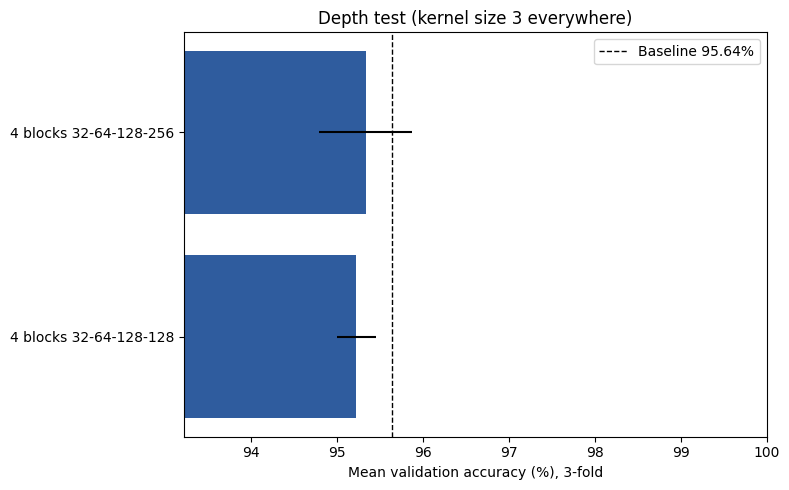

In [9]:
plot_df = res.sort_values("val_acc_mean")
cols = ["#3F9E4D" if "baseline" in k else "#2F5C9E" for k in plot_df["filters"]]
plt.figure(figsize=(8, 5))
plt.barh(plot_df["filters"], plot_df["val_acc_mean"], xerr=plot_df["val_acc_std"], color=cols)
plt.axvline(base, color="k", linestyle="--", linewidth=1, label=f"Baseline {base:.2f}%")
plt.xlim(max(0, plot_df["val_acc_mean"].min() - 2), 100)
plt.xlabel(f"Mean validation accuracy (%), {FOLDS}-fold"); plt.legend()
plt.title("Depth test (kernel size 3 everywhere)")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/depth_search.png", dpi=150); plt.show()